# K-means clustering with the features selected for each comparison

Same notebook as `kmeans_exploration_new.ipynb`, but it uses the features chosen by `select_features.py` for **one comparison** (`COMPARISON` in the settings):

- input: `RESULTSNatalia/feature_selection/features_selected_<COMPARISON>.xlsx` (only the sessions of the groups of that comparison)
- results: `RESULTSNatalia/kmeans_new_selection/<COMPARISON>/<feature set>_k<K>/`, so nothing older is overwritten

To run another comparison, change `COMPARISON` and **Run All** again.

**Goal:** see if the sessions form natural groups, **watch how k-means finds them step by step**, and then **look at the feature values** to understand what makes each cluster different.

### How k-means works (in words)
1. **Start:** put *k* centres somewhere in the feature space.
2. **Assign:** every session goes to its **nearest** centre → this makes *k* clusters.
3. **Update:** move every centre to the **average** of the sessions assigned to it.
4. **Repeat** 2 and 3 until the centres stop moving.

It is **unsupervised**: k-means never sees the group labels. At the end we compare its clusters with the real groups.

### Important about the pictures
K-means works in the **full feature space** (all your standardized features at once), which we cannot draw. To *see* it, every step is projected onto **two principal components**, like a shadow on a wall. So two points that look close in the picture may be far apart in the full space: the picture is a guide, the computation uses all the features.

### Why PC1 and PC2?
They are the two directions where the sessions differ the most, so they are the "most informative shadow". **You can choose any pair** with `PC_X` and `PC_Y` in the settings, and section 3 shows a grid with **every pair** of the first PCs at once.

### Feature families
You can run the notebook on one family at a time with `FEATURE_SET` (`"all"`, `"ripple"`, `"CSD"` or `"power"`; power can be split with `POWER_LAYER`, `POWER_STATE`, `POWER_STAT`). With the selected features some families may have very few features (or none) for a comparison: section 1 prints how many there are.

**Run the cells in order** (Shift + Enter). Keep this notebook in the same folder as `pca_analysis_new_selection.py`.

## 1. Settings and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, kmeans_plusplus
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Same folders, columns and data loading as the PCA (pca_analysis_new_selection.py, same folder)
import pca_analysis_new_selection as cfg

# ---------------- SETTINGS ----------------
COMPARISON = "NPC_vs_EFV"   # "WT_vs_NPC", "NPC_vs_EFV", "WT_vs_EFV" or "WT_vs_NPC_vs_EFV"
K = 2                 # number of clusters (2 for a pair, 3 for the three groups; see section 1b)
INIT = "random"       # "random": k random sessions as starting centres (more movement to watch)
                      # "k-means++": smart start, far-apart centres (what sklearn uses)
SEED = 0              # change it to see another random start
MAX_ITER = 50
PC_X, PC_Y = 1, 2     # which principal components are used for the 2-D pictures
N_PCS_GRID = 4        # the "all pairs" grid shows PC1 ... PC{N_PCS_GRID}
FEATURE_FILTER = None # section 4b: None = all features, or text, e.g. "Theta", "SLM"

# Which FAMILY of features k-means uses (see the table printed below):
FEATURE_SET = "all"   # "all", "ripple", "CSD" or "power"
# Only for FEATURE_SET = "power" (None = keep all):
POWER_LAYER = None    # "PYR" or "SLM"
POWER_STATE = None    # "Theta" (theta periods) or "LIA" (LIA periods)
POWER_STAT = None     # "mean" or "max"

set_name = "_".join(str(v) for v in [FEATURE_SET, POWER_LAYER, POWER_STATE, POWER_STAT]
                    if v is not None and (FEATURE_SET == "power" or v == FEATURE_SET))
OUTPUT_DIR = cfg.output_dir("kmeans", COMPARISON) / f"{set_name}_k{K}"
CLUSTER_COLORS = ["#7b3294", "#e66101", "#018571", "#e7298a", "#a6761d",
                  "#1f78b4", "#666666", "#b2df8a", "#fb9a99", "#cab2d6"]   # up to K = 10
CLUSTER_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*", "h", "<"]
# ------------------------------------------

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

In [2]:
ids, feats = cfg.load_data(cfg.excel_for(COMPARISON), cfg.SHEET, cfg.ID_COLS)
groups = ids[cfg.GROUP_COL].astype(str).to_numpy()
animals = ids["animal"].astype(str).to_numpy()
import re
POWER_RE = re.compile(r"^(Delta|Theta|Alpha|SlowGamma|MidGamma|FastGamma|Ripple)_(PYR|SLM)_(Theta|LIA)_(mean|max)$",
                      re.IGNORECASE)

def feature_family(name):
    if POWER_RE.match(name):
        return "power"
    if name.upper().startswith("CSD_"):
        return "CSD"
    if name.lower().startswith("ripple_"):
        return "ripple"
    return "other"

families = pd.Series({f: feature_family(f) for f in feats.columns}, name="family")
print(f"Comparison {COMPARISON}: selected features per family:")
for fam, cols in families.groupby(families).groups.items():
    print(f"  {fam:7s} {len(cols):3d} features")

keep = list(feats.columns) if FEATURE_SET == "all" else list(families.index[families == FEATURE_SET])
if FEATURE_SET == "power":
    for part, val in [(1, POWER_LAYER), (2, POWER_STATE), (3, POWER_STAT)]:
        if val is not None:
            keep = [f for f in keep if POWER_RE.match(f).group(part + 1).lower() == val.lower()]
if len(keep) < 2:
    raise ValueError(f"Only {len(keep)} feature(s) for {COMPARISON} with FEATURE_SET = '{FEATURE_SET}': "
                     "k-means needs at least 2. Use FEATURE_SET = 'all' or another family.")
feats = feats[keep]
feature_names = keep
print(f"\nUsing feature set '{set_name}': {len(keep)} features -> results in {OUTPUT_DIR}")

X = StandardScaler().fit_transform(feats.to_numpy())   # z-scores, same as the PCA
print(f"{X.shape[0]} sessions x {X.shape[1]} features")
print(pd.Series(groups).value_counts().to_dict())

# PCA used ONLY for the pictures (k-means itself uses all the features)
n_pc = min(max(PC_X, PC_Y, N_PCS_GRID), X.shape[1], X.shape[0])
pca = PCA(n_components=n_pc).fit(X)
P_all = pca.transform(X)                     # sessions on PC1 ... PC{n_pc}
var_all = pca.explained_variance_ratio_ * 100
pcs = [PC_X - 1, PC_Y - 1]

def proj(A):
    # Coordinates of any points (sessions or centres) on the chosen pair of PCs
    return pca.transform(np.atleast_2d(A))[:, pcs]

P = P_all[:, pcs]
var2 = var_all[pcs]
xlab, ylab = f"PC{PC_X} ({var2[0]:.0f}%)", f"PC{PC_Y} ({var2[1]:.0f}%)"
pair_name = f"PC{PC_X}-PC{PC_Y}"
print("Variance explained by each PC: " +
      ", ".join(f"PC{i + 1} {v:.0f}%" for i, v in enumerate(var_all)))
print(f"The {pair_name} picture shows {var2.sum():.0f}% of the variance")

[!] Removed 4 row(s) with missing values
Comparison NPC_vs_EFV: selected features per family:
  CSD       1 features
  power    16 features

Using feature set 'all': 17 features -> results in D:\Violeta\ANALISIS\RESULTSNatalia\kmeans_new_selection\NPC_vs_EFV\all_k2
75 sessions x 17 features
{'NPC': 40, 'EFV': 35}
Variance explained by each PC: PC1 54%, PC2 29%, PC3 8%, PC4 5%
The PC1-PC2 picture shows 83% of the variance


In [3]:
# Sessions of the "odd subgroup" (if check_odd_subgroup.py was run), to mark them later
odd_file = cfg.RESULTS_DIR / "embedding_results" / "subgroup_check" / "subgroup_check.xlsx"
odd = np.zeros(len(ids), bool)
if odd_file.exists():
    o = pd.read_excel(odd_file, sheet_name="subgroup_sessions")
    odd_keys = set(o["animal"].astype(str) + "|" + o["session"].astype(str))
    odd = (ids["animal"].astype(str) + "|" + ids["session"].astype(str)).isin(odd_keys).to_numpy()
    print(f"Odd subgroup found: {odd.sum()} sessions of this comparison (they will be circled in black)")
else:
    print("No odd-subgroup file found (fine, it is optional)")

No odd-subgroup file found (fine, it is optional)


### 1b. How many clusters does the data support?
Before choosing `K`, k-means is run (with `sklearn`) for k = 2 ... 8:
- **Elbow (inertia):** always goes down with more clusters; look for the *elbow* where it stops dropping fast.
- **Silhouette:** how well separated the clusters are. Higher is better (≈0.5 or more = clear clusters, ≈0.25 = weak, ≈0 = no real structure).
- **Biggest cluster of one mouse:** for each k, the largest share of a cluster that comes from a single mouse. If it approaches 100%, the clusters are just *individual mice*, not subgroups of the disease.

Choose `K` in the settings, then **Run All** again.

c:\Users\natal\anaconda3\envs\niemannpick\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\natal\anaconda3\envs\niemannpick\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\natal\anaconda3\envs\niemannpick\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\natal\anaconda3\envs\niemannpick\Lib\site-packages\sklearn\cluster\_kmeans.p

,k,inertia,silhouette,ARI vs groups,biggest share of one mouse
0,2,792.95,0.49,0.14,0.28
1,3,528.55,0.53,0.10,1.00
2,4,421.21,0.47,0.13,1.00
3,5,348.31,0.26,0.21,1.00
4,6,303.59,0.26,0.15,1.00
5,7,262.14,0.29,0.16,1.00
6,8,232.82,0.29,0.16,1.00


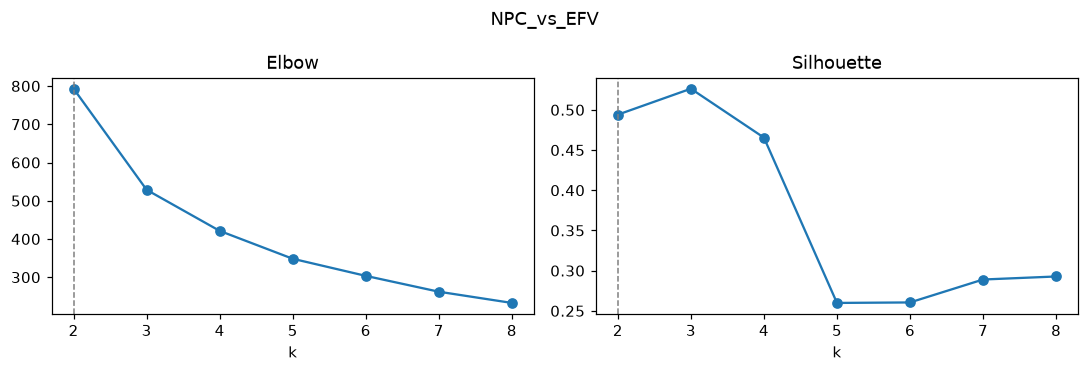

In [4]:
res_k = []
for k in range(2, min(9, len(X))):
    m = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    one_mouse = max(pd.Series(animals[m.labels_ == c]).value_counts(normalize=True).iloc[0]
                    for c in range(k))
    res_k.append((k, m.inertia_, silhouette_score(X, m.labels_),
                  adjusted_rand_score(groups, m.labels_), one_mouse))
res_k = pd.DataFrame(res_k, columns=["k", "inertia", "silhouette", "ARI vs groups",
                                     "biggest share of one mouse"])
display(res_k.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(res_k["k"], res_k["inertia"], "o-"); axes[0].set_title("Elbow"); axes[0].set_xlabel("k")
axes[1].plot(res_k["k"], res_k["silhouette"], "o-"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("k")
for ax in axes:
    ax.axvline(K, color="gray", ls="--", lw=1)
fig.suptitle(COMPARISON)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "00_choose_k.png", dpi=200); plt.show()

### 1c. A proxy for disease progression
We use the **recording date** in the session folder name: for every session, the **number of days since the first recording of that same mouse**. Later sessions = mice further along in the disease. Sessions whose name has no date (e.g. `P-7`) get no value.

In [5]:
def parse_date(name):
    s = str(name)
    for pat, order in [(r"(\d{4})[-_.](\d{1,2})[-_.](\d{1,2})", "ymd"),
                       (r"(\d{1,2})[-_.](\d{1,2})[-_.](\d{4})", "dmy"),
                       (r"(20\d{2})(\d{2})(\d{2})", "ymd")]:
        m = re.search(pat, s)
        if m:
            a, b, c = (int(x) for x in m.groups())
            y, mo, d = (a, b, c) if order == "ymd" else (c, b, a)
            try:
                return pd.Timestamp(year=y, month=mo, day=d)
            except ValueError:
                pass
    return pd.NaT

rec_date = ids["session"].map(parse_date)
days_in_study = (rec_date - rec_date.groupby(ids["animal"]).transform("min")).dt.days.to_numpy(float)
session_order = rec_date.groupby(ids["animal"]).rank(method="first").to_numpy(float)
print(f"Sessions with a readable date: {rec_date.notna().sum()} of {len(ids)}")
if rec_date.isna().any():
    print("Without date:", sorted(ids.loc[rec_date.isna(), "session"].astype(str).unique()))

Sessions with a readable date: 65 of 75
Without date: ['P-1', 'P-3', 'P-7', 'P1-HI', 'P3-HD', 'P3-HI', 'P4-HI', 'P5-HI', 'P6-HD', 'P7-HD']


## 2. K-means step by step

We write k-means ourselves (it is only a few lines) so that we can **save every step**: the centres, which cluster every session belongs to, and the **inertia**.

**Inertia** = sum of the squared distances from every session to its centre. It measures how "tight" the clusters are, and it can only go down at every step. When it stops going down, k-means has finished (*converged*).

In [6]:
def kmeans_with_history(X, k, init="random", seed=0, max_iter=50):
    rng = np.random.default_rng(seed)
    if init == "random":
        centres = X[rng.choice(len(X), size=k, replace=False)].copy()
    else:
        centres, _ = kmeans_plusplus(X, n_clusters=k, random_state=seed)

    history = []
    for it in range(max_iter):
        # STEP "assign": distance of every session to every centre -> nearest one
        dist2 = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
        labels = dist2.argmin(axis=1)
        inertia = dist2[np.arange(len(X)), labels].sum()
        history.append({"centres": centres.copy(), "labels": labels.copy(), "inertia": inertia})

        # STEP "update": every centre moves to the mean of its sessions
        new_centres = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centres[j]
                                for j in range(k)])
        if np.allclose(new_centres, centres):
            break   # centres did not move -> converged
        centres = new_centres
    return history


history = kmeans_with_history(X, K, init=INIT, seed=SEED, max_iter=MAX_ITER)
print(f"Converged after {len(history)} steps")
for i, h in enumerate(history):
    sizes = np.bincount(h["labels"], minlength=K)
    print(f"step {i:2d}: inertia = {h['inertia']:8.1f}   cluster sizes = {sizes.tolist()}")

Converged after 6 steps
step  0: inertia =   1354.3   cluster sizes = [46, 29]
step  1: inertia =    949.5   cluster sizes = [35, 40]
step  2: inertia =    880.6   cluster sizes = [24, 51]
step  3: inertia =    815.2   cluster sizes = [19, 56]
step  4: inertia =    795.3   cluster sizes = [18, 57]
step  5: inertia =    792.9   cluster sizes = [18, 57]


### 2a. The steps as a grid of pictures
Each panel is one step. Sessions are colored by the cluster they belong to **at that step**; the big **X** marks are the centres, and the thin line behind each X is the path it has travelled so far.

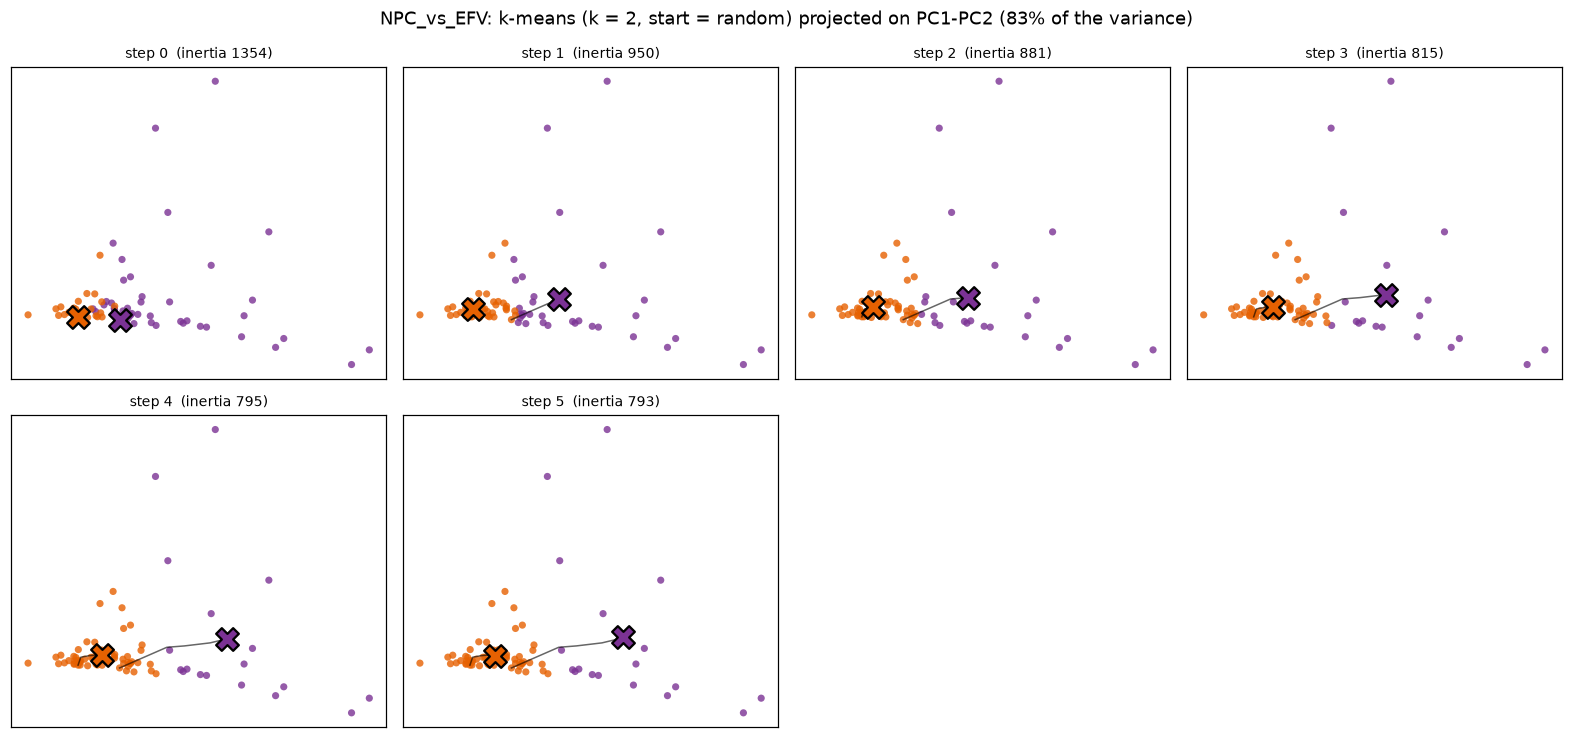

In [7]:
def draw_step(ax, i, title=True):
    h = history[i]
    C = proj(h["centres"])
    for j in range(K):
        m = h["labels"] == j
        ax.scatter(P[m, 0], P[m, 1], s=22, color=CLUSTER_COLORS[j], alpha=0.8, edgecolor="none")
        path = proj(np.array([history[t]["centres"][j] for t in range(i + 1)]))
        ax.plot(path[:, 0], path[:, 1], "-", color="k", lw=1, alpha=0.6)
        ax.scatter(C[j, 0], C[j, 1], marker="X", s=220, color=CLUSTER_COLORS[j],
                   edgecolor="k", linewidth=1.5, zorder=5)
    if title:
        ax.set_title(f"step {i}  (inertia {h['inertia']:.0f})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])


n_show = min(len(history), 8)
steps = np.unique(np.linspace(0, len(history) - 1, n_show).round().astype(int))
ncol = min(4, len(steps))
nrow = int(np.ceil(len(steps) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.4 * nrow), squeeze=False)
for ax, i in zip(axes.flat, steps):
    draw_step(ax, i)
for ax in axes.flat[len(steps):]:
    ax.axis("off")
fig.suptitle(f"{COMPARISON}: k-means (k = {K}, start = {INIT}) projected on {pair_name} "
             f"({var2.sum():.0f}% of the variance)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_kmeans_steps.png", dpi=200)
plt.show()

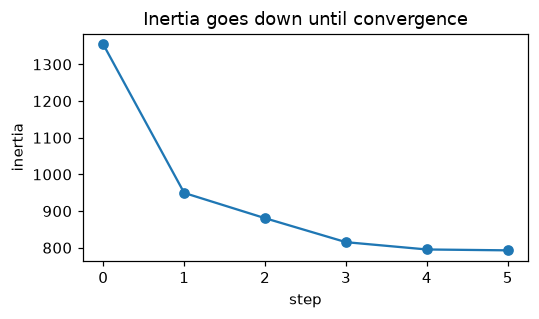

In [8]:
# Inertia at every step: it must always go down
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([h["inertia"] for h in history], "o-")
ax.set_xlabel("step"); ax.set_ylabel("inertia"); ax.set_title("Inertia goes down until convergence")
fig.tight_layout(); plt.show()

### 2b. Does the starting point matter?
K-means can end in different solutions depending on where the centres start. `sklearn` runs it many times (`n_init`) and keeps the run with the **lowest inertia**. Here we run our version with 10 different seeds and compare it with `sklearn`.

In [9]:
finals = []
for s in range(10):
    h = kmeans_with_history(X, K, init=INIT, seed=s, max_iter=MAX_ITER)
    finals.append((s, h[-1]["inertia"], len(h)))
print(pd.DataFrame(finals, columns=["seed", "final inertia", "steps"]).to_string(index=False))

km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
labels = km.labels_          # <- the clusters used from here on
print(f"\nsklearn best inertia: {km.inertia_:.1f}")
print(f"Same partition as our run with SEED={SEED}? "
      f"ARI = {adjusted_rand_score(labels, history[-1]['labels']):.2f} (1 = identical)")

 seed  final inertia  steps
    0     792.947309      6
    1     804.373283      7
    2     795.347873      3
    3     792.947309      6
    4     804.373283      5
    5     804.373283      6
    6     798.732103      5
    7     792.947309      5
    8     792.947309      6
    9     798.732103      4

sklearn best inertia: 792.9
Same partition as our run with SEED=0? ARI = 1.00 (1 = identical)


c:\Users\natal\anaconda3\envs\niemannpick\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## 3. Do the clusters match the study groups?

- **Table:** how many sessions of each group fall in each cluster. If k-means had found the groups, each row would be mostly one group.
- **ARI (Adjusted Rand Index):** 1 = clusters identical to the groups, 0 = no better than random.
- We also check whether clusters follow **animals** or the **odd subgroup** instead of the groups.

In [10]:
print("Clusters vs GROUPS:")
display(pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(groups, name="group"), margins=True))
print(f"ARI clusters vs groups: {adjusted_rand_score(groups, labels):.2f}")
print(f"Silhouette of the clusters: {silhouette_score(X, labels):.2f}")

print("\nClusters vs ANIMALS (sessions of each mouse in each cluster):")
display(pd.crosstab(pd.Series(animals, name="animal"), pd.Series(labels, name="cluster")))

if odd.any():
    print("Clusters vs ODD SUBGROUP:")
    display(pd.crosstab(pd.Series(labels, name="cluster"),
                        pd.Series(np.where(odd, "odd", "normal"), name="session")))

Clusters vs GROUPS:


group,EFV,NPC,All
cluster,,,
0,20,37,57
1,15,3,18
All,35,40,75


ARI clusters vs groups: 0.14
Silhouette of the clusters: 0.49

Clusters vs ANIMALS (sessions of each mouse in each cluster):


cluster,0,1
animal,,
EFV_218,2,5
EFV_220,4,4
EFV_277,7,0
EFV_279,5,1
EFV_280,2,5
NPC_249,9,0
NPC_250,7,1
NPC_262,10,0
NPC_28,2,1


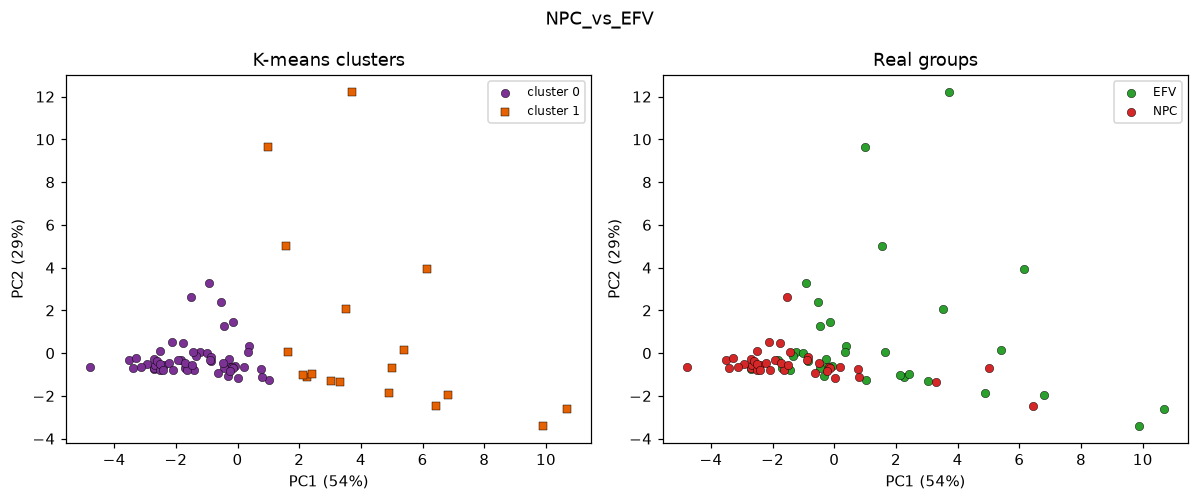

In [11]:
# Side by side: colored by k-means cluster vs colored by real group
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for j in range(K):
    m = labels == j
    axes[0].scatter(P[m, 0], P[m, 1], s=30, color=CLUSTER_COLORS[j], marker=CLUSTER_MARKERS[j],
                    edgecolor="k", linewidth=0.3, label=f"cluster {j}")
for gi, g in enumerate(pd.unique(groups)):
    m = groups == g
    axes[1].scatter(P[m, 0], P[m, 1], s=30, color=cfg.color_for(g, gi), edgecolor="k",
                    linewidth=0.3, label=g)
for ax in axes:
    if odd.any():
        ax.scatter(P[odd, 0], P[odd, 1], s=110, facecolor="none", edgecolor="k", lw=1.2,
                   label="odd subgroup")
    ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    ax.legend(fontsize=8)
axes[0].set_title("K-means clusters"); axes[1].set_title("Real groups")
fig.suptitle(COMPARISON)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "02_clusters_vs_groups.png", dpi=200); plt.show()

### 3b. Every pair of principal components
One 2-D picture only shows two directions. Here are **all the pairs** of the first PCs (colored by k-means cluster). On the diagonal: how each cluster is distributed along that single PC. If the clusters overlap in one pair but separate in another, the separating information lives in those other PCs.

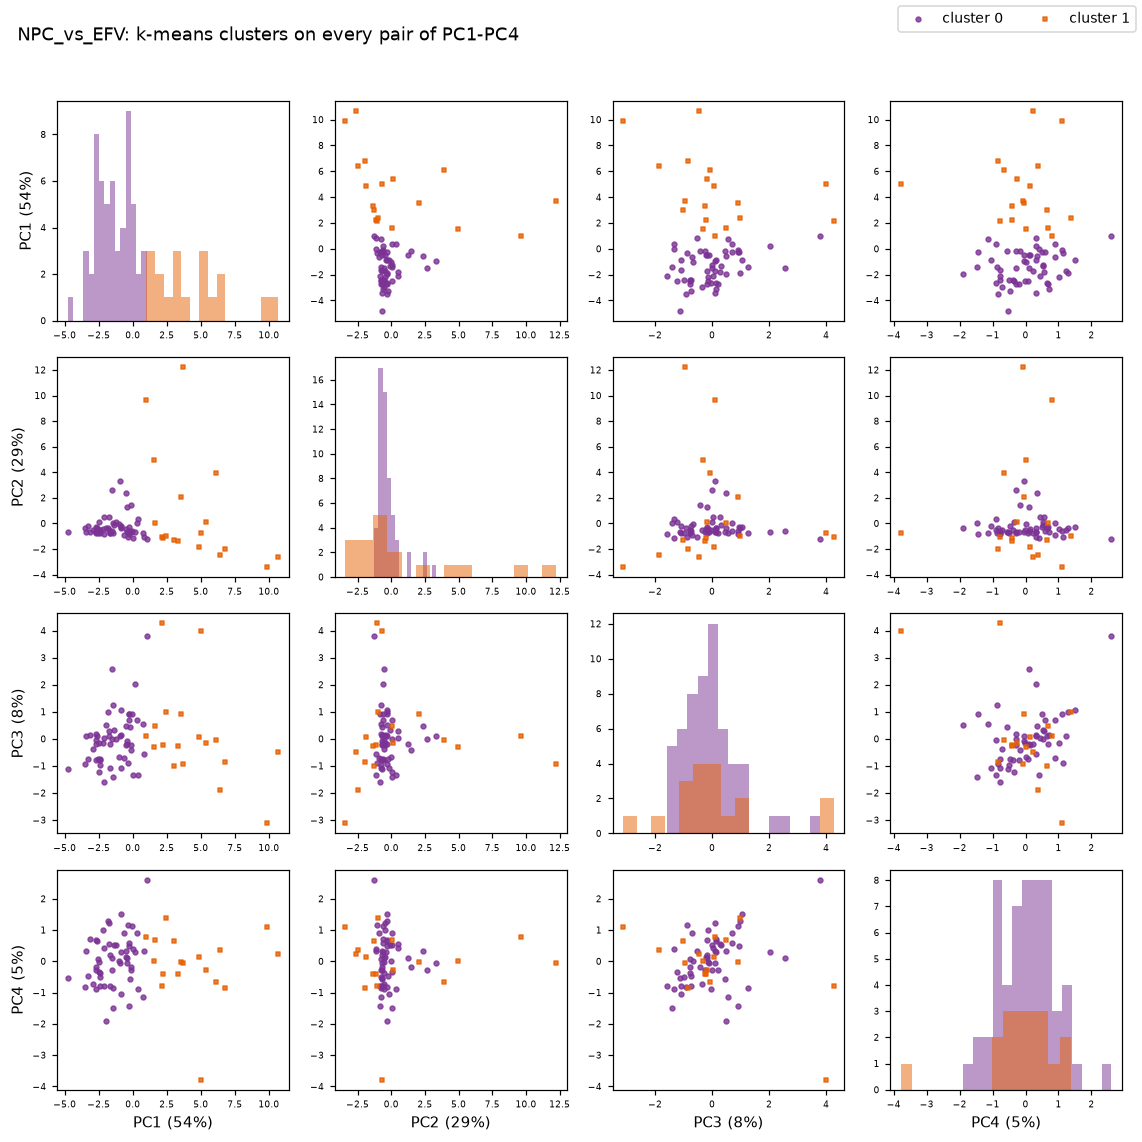

In [12]:
n = P_all.shape[1]
fig, axes = plt.subplots(n, n, figsize=(2.6 * n, 2.6 * n), squeeze=False)
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        for c in range(K):
            m = labels == c
            if i == j:
                ax.hist(P_all[m, i], bins=15, alpha=0.5, color=CLUSTER_COLORS[c])
            else:
                ax.scatter(P_all[m, j], P_all[m, i], s=10, color=CLUSTER_COLORS[c],
                           marker=CLUSTER_MARKERS[c], alpha=0.8,
                           label=f"cluster {c}" if (i, j) == (0, 1) else None)
        if i == n - 1:
            ax.set_xlabel(f"PC{j + 1} ({var_all[j]:.0f}%)")
        if j == 0:
            ax.set_ylabel(f"PC{i + 1} ({var_all[i]:.0f}%)")
        ax.tick_params(labelsize=6)
fig.legend(loc="upper right", ncol=K, fontsize=9)
fig.suptitle(f"{COMPARISON}: k-means clusters on every pair of PC1-PC{n}", x=0.02, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(OUTPUT_DIR / "02b_clusters_all_pc_pairs.png", dpi=200)
plt.show()

### 3c. What is inside each cluster? (subgroups and progression)
- **Left:** the composition of each cluster by group. A cluster that is mostly one group is a candidate **subgroup** of that group.
- **Middle:** how many different mice each cluster contains. A cluster made of 1-2 mice is probably "those mice", not a disease subgroup.
- **Right:** days since the first recording of each mouse, per cluster. If a cluster has clearly later (or earlier) sessions than the others, it may reflect **disease progression**.

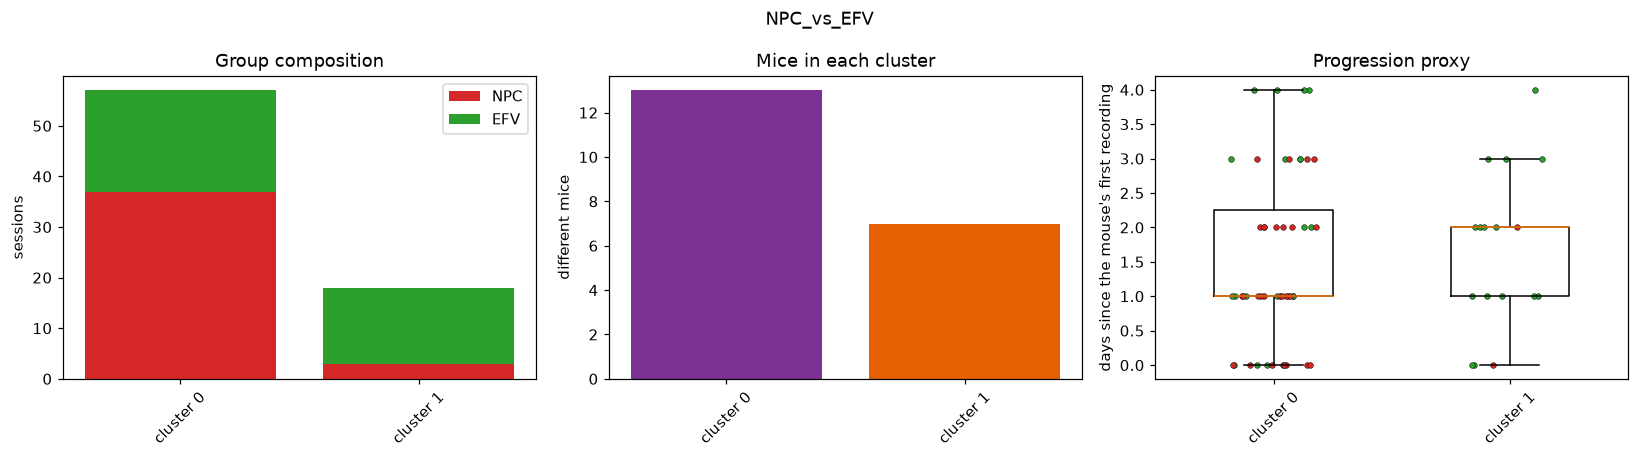

,sessions,mice,median_days_in_study,NPC,EFV
0,57,13,1.0,37,20
1,18,7,2.0,3,15


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# composition by group
comp = pd.crosstab(labels, groups).reindex(columns=[g for g in ["WT", "NPC", "EFV"] if g in set(groups)])
bottom = np.zeros(len(comp))
for gi, g in enumerate(comp.columns):
    axes[0].bar(comp.index, comp[g], bottom=bottom, color=cfg.color_for(g, gi), label=g)
    bottom += comp[g].to_numpy()
axes[0].set_xticks(comp.index, [f"cluster {c}" for c in comp.index], rotation=45)
axes[0].set_ylabel("sessions"); axes[0].set_title("Group composition"); axes[0].legend()

# number of mice per cluster
n_mice = pd.Series(animals).groupby(labels).nunique()
axes[1].bar(n_mice.index, n_mice.values, color=[CLUSTER_COLORS[c] for c in n_mice.index])
axes[1].set_xticks(n_mice.index, [f"cluster {c}" for c in n_mice.index], rotation=45)
axes[1].set_ylabel("different mice"); axes[1].set_title("Mice in each cluster")

# progression proxy
rng = np.random.default_rng(0)
for c in range(K):
    m = (labels == c) & ~np.isnan(days_in_study)
    if m.any():
        axes[2].boxplot(days_in_study[m], positions=[c], widths=0.5, showfliers=False)
    for gi, g in enumerate(pd.unique(groups)):
        mg = m & (groups == g)
        axes[2].scatter(c + rng.uniform(-0.18, 0.18, mg.sum()), days_in_study[mg], s=14,
                        color=cfg.color_for(g, gi), edgecolor="k", linewidth=0.3)
axes[2].set_xticks(range(K), [f"cluster {c}" for c in range(K)], rotation=45)
axes[2].set_ylabel("days since the mouse's first recording")
axes[2].set_title("Progression proxy")
fig.suptitle(COMPARISON)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "02c_cluster_composition_progression.png", dpi=200)
plt.show()

summary = pd.DataFrame({
    "sessions": pd.Series(labels).value_counts().sort_index(),
    "mice": n_mice,
    "median_days_in_study": pd.Series(days_in_study).groupby(labels).median(),
})
summary = summary.join(comp)
display(summary)

## 4. Looking at the data through the feature values

All values are **z-scores**: 0 = average session, **red = higher** than average, **blue = lower** (in standard deviations).

### 4a. Cluster profiles (the easiest to read)
One row per cluster, one column per feature: the **average z-score** of the sessions in that cluster. A strong red or blue cell is a feature that characterizes that cluster. Below it, the same for the real groups, for comparison.

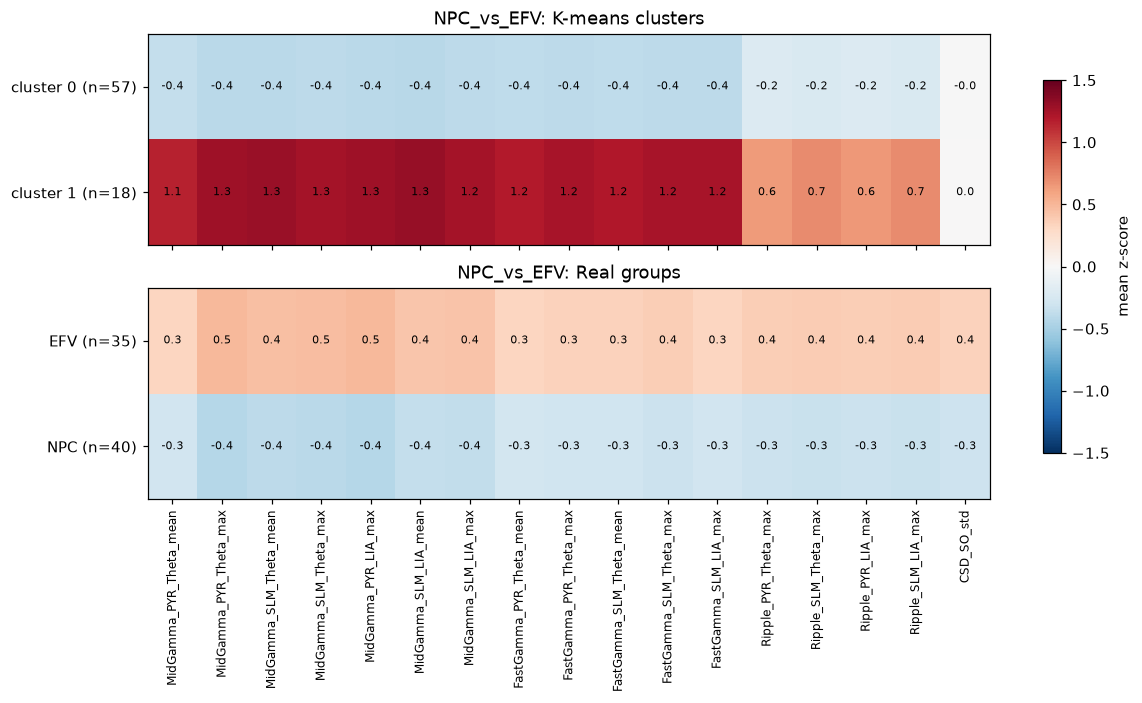

In [14]:
Z = pd.DataFrame(X, columns=feature_names)
prof_cluster = Z.groupby(labels).mean()
prof_cluster.index = [f"cluster {j} (n={np.sum(labels == j)})" for j in prof_cluster.index]
prof_group = Z.groupby(groups).mean()
prof_group.index = [f"{g} (n={np.sum(groups == g)})" for g in prof_group.index]

lim = max(1.0, np.ceil(max(prof_cluster.abs().max().max(), prof_group.abs().max().max()) * 2) / 2)
fig, axes = plt.subplots(2, 1, figsize=(0.55 * len(feature_names) + 3, 5.5),
                         gridspec_kw={"height_ratios": [K, len(prof_group)]})
for ax, prof, title in [(axes[0], prof_cluster, "K-means clusters"), (axes[1], prof_group, "Real groups")]:
    im = ax.imshow(prof.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(prof)), prof.index)
    ax.set_xticks(range(len(feature_names)), feature_names if ax is axes[1] else [], rotation=90, fontsize=8)
    if prof.shape[1] <= 30:          # numbers only when they fit
        for r in range(prof.shape[0]):
            for c in range(prof.shape[1]):
                ax.text(c, r, f"{prof.values[r, c]:.1f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{COMPARISON}: {title}")
fig.colorbar(im, ax=axes, label="mean z-score", shrink=0.8)
fig.savefig(OUTPUT_DIR / "03_profiles.png", dpi=200, bbox_inches="tight"); plt.show()

### 4b. The PCA picture colored by each feature
One small panel per feature: the same 2-D picture (the pair `PC_X`-`PC_Y` from the settings), but each session is colored by **its value of that feature**. Marker shape = k-means cluster. A feature whose colors change smoothly along the cloud is one that "drives" that direction; if red and blue are mixed everywhere, that feature does not shape the clusters.

You can show only some features with `FEATURE_FILTER` in the settings (e.g. `"CSD"`, `"Theta"`, `"SLM"`, `"ripple"`).

Showing 17 of 17 features


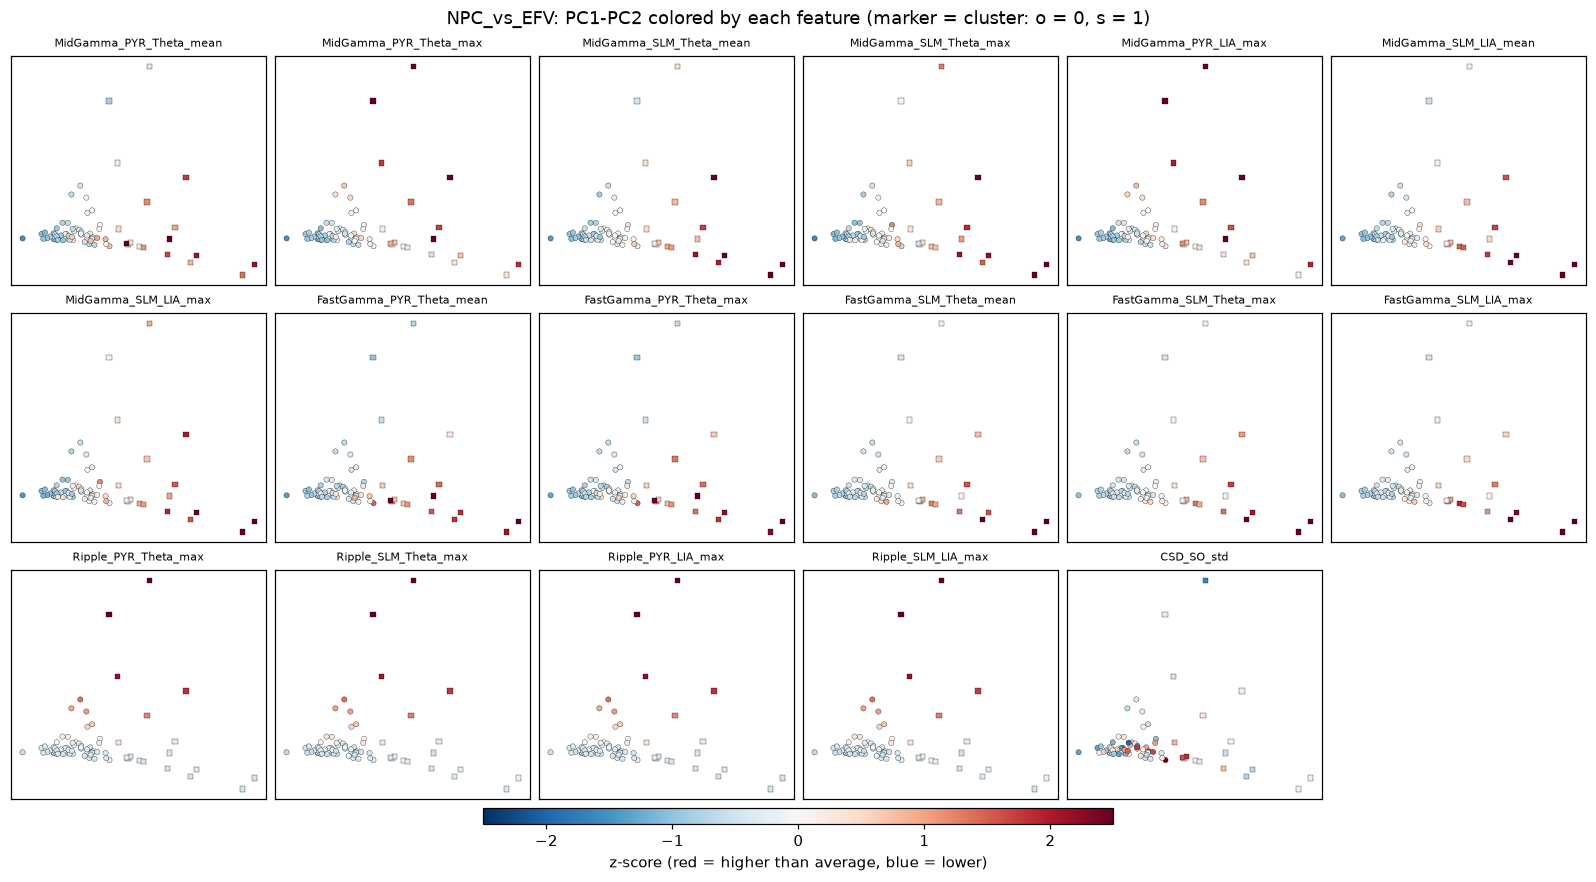

In [15]:
show = [f for f in feature_names if FEATURE_FILTER is None or FEATURE_FILTER.lower() in f.lower()]
print(f"Showing {len(show)} of {len(feature_names)} features")
ncol = min(6, len(show))
nrow = int(np.ceil(len(show) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.4 * ncol, 2.3 * nrow + 1.0), squeeze=False,
                         layout="constrained")
for n, f in enumerate(show):
    ax = axes.flat[n]
    col = feature_names.index(f)
    for j in range(K):
        m = labels == j
        sc = ax.scatter(P[m, 0], P[m, 1], c=np.clip(X[m, col], -2.5, 2.5), cmap="RdBu_r",
                        vmin=-2.5, vmax=2.5, s=12, marker=CLUSTER_MARKERS[j],
                        edgecolor="k", linewidth=0.2)
    ax.set_title(f, fontsize=7); ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[len(show):]:
    ax.axis("off")
fig.colorbar(sc, ax=axes, location="bottom", shrink=0.4, aspect=40, pad=0.01,
             label="z-score (red = higher than average, blue = lower)")
fig.suptitle(f"{COMPARISON}: {pair_name} colored by each feature (marker = cluster: " +
             ", ".join(f"{CLUSTER_MARKERS[j]} = {j}" for j in range(K)) + ")")
fig.savefig(OUTPUT_DIR / "05_pca_by_feature.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Save the cluster of every session

In [16]:
out = ids.copy()
out["cluster"] = labels
out["odd_subgroup"] = odd
out["days_since_first_recording"] = days_in_study
out["session_number_of_mouse"] = session_order
for i in range(P_all.shape[1]):
    out[f"PC{i + 1}"] = P_all[:, i]
with pd.ExcelWriter(OUTPUT_DIR / "kmeans_results.xlsx") as w:
    out.to_excel(w, sheet_name="sessions", index=False)
    prof_cluster.to_excel(w, sheet_name="cluster_profiles")
    prof_group.to_excel(w, sheet_name="group_profiles")
    res_k.to_excel(w, sheet_name="choose_k", index=False)
    pd.DataFrame({"setting": ["COMPARISON", "K", "FEATURE_SET", "n_features", "n_sessions"],
                  "value": [COMPARISON, K, set_name, len(feature_names), len(X)]}
                 ).to_excel(w, sheet_name="settings", index=False)
print(f"Saved in {OUTPUT_DIR}")

Saved in D:\Violeta\ANALISIS\RESULTSNatalia\kmeans_new_selection\NPC_vs_EFV\all_k2
